In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report



In [2]:
iris=load_iris()
x=iris.data[:,[2,3]]
y=iris.target


In [3]:
#Split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)

In [4]:
print(type(x_train))
print(type(x_test))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [5]:
#Scaling
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [6]:
#mulitiple models
kernels=['linear','poly','rbf']
C_value=[0.1,1,10]

best=0

for k in kernels:
    for c in C_value:
        model=SVC(kernel=k,C=c)
        model.fit(x_train,y_train)
        pred=model.predict(x_test)

        acc=accuracy_score(y_test,pred)

        print(k,c,acc)

        if acc>best:
            best=acc
            best_model=(k,c)

#best model
print("Best Model: ",best_model)
print("Best Accuracy: ",best)


linear 0.1 0.9333333333333333
linear 1 0.9333333333333333
linear 10 0.9333333333333333
poly 0.1 0.8666666666666667
poly 1 0.9333333333333333
poly 10 0.9333333333333333
rbf 0.1 0.9333333333333333
rbf 1 0.9333333333333333
rbf 10 0.9333333333333333
Best Model:  ('linear', 0.1)
Best Accuracy:  0.9333333333333333


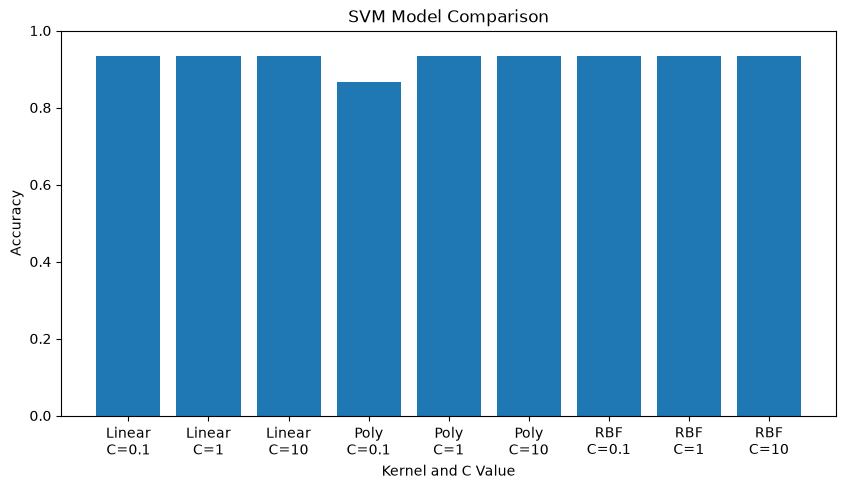

In [7]:
import matplotlib.pyplot as plt
import numpy as np

kernels = ['Linear', 'Linear', 'Linear',
           'Poly', 'Poly', 'Poly',
           'RBF', 'RBF', 'RBF']

C_values = [0.1, 1, 10] * 3

accuracies = [
    0.9333, 0.9333, 0.9333,
    0.8667, 0.9333, 0.9333,
    0.9333, 0.9333, 0.9333
]

labels = [f'{k}\nC={c}' for k, c in zip(kernels, C_values)]

plt.figure(figsize=(10, 5))
plt.bar(labels, accuracies)

plt.xlabel('Kernel and C Value')
plt.ylabel('Accuracy')
plt.title('SVM Model Comparison')
plt.ylim(0, 1)

plt.show()

Write a Python program to implement Support Vector Machine (SVM) classification using the Iris dataset. Split the dataset into training and testing sets, perform feature scaling, and compare the performance of Linear, Polynomial, and RBF kernels using different values of the regularization parameter C (0.1, 1, 10). Calculate the accuracy for each model, display the results, and identify the best-performing model.